#### GQA Token Score Layer Cosine Analysis

In [ ]:
from pathlib import Path
import json
import re
import numpy as np
import matplotlib.pyplot as plt

try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **kwargs):
        return x

BASE_ROOT = Path('/RobustPruner_2026/RobustPruner/glimpse_qwen_eval/token_scores')
RUN_DIRS = {
    'original': BASE_ROOT / 'gqa_rand_seed42_20000',
    'concise_rephrase': BASE_ROOT / 'text_perturbations_concise_rephrase',
    'synonym_replacement': BASE_ROOT / 'text_perturbations_synonym_replacement',
    'sentence_structure_change': BASE_ROOT / 'text_perturbations_sentence_structure_change',
    'advanced_vocabulary': BASE_ROOT / 'text_perturbations_advanced_vocabulary',
}

FILE_GLOB = 'gqa_rand_seed42_20000_*.json'
SKIP_BAD_FILES = True

INCLUDE_TOP_LEVEL_LAST_LAYER = False
TOP_LAYER_PREFIX = 'top_last_layer'

for k, v in RUN_DIRS.items():
    print(f'{k:28s} -> {v} (exists={v.exists()})')


In [6]:
def numeric_suffix(path: Path) -> int:
    m = re.search(r'(\d+)\.json$', path.name)
    return int(m.group(1)) if m else 10**18

def safe_corr(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    if a.size == 0 or b.size == 0:
        return np.nan
    if a.size != b.size:
        n = min(a.size, b.size)
        a = a[:n]
        b = b[:n]
    if np.std(a) == 0.0 or np.std(b) == 0.0:
        return np.nan
    return float(np.corrcoef(a, b)[0, 1])

def extract_layer_corrs(obj, include_top_level=False):
    out = {}
    per_layer = obj.get('per_layer_text_to_visual', {}) or {}

    for key, payload in per_layer.items():
        if not isinstance(payload, dict):
            continue
        layer_idx = payload.get('layer_index_1based')
        if layer_idx is None:
            m = re.match(r'layer_(\d+)$', str(key))
            if m:
                layer_idx = int(m.group(1))
        if layer_idx is None:
            continue

        attn = payload.get('text_to_visual_attention', [])
        sim = payload.get('text_to_visual_similarity', [])
        c = safe_corr(attn, sim)
        if not np.isnan(c):
            out[int(layer_idx)] = c

    if include_top_level:
        top_attn = obj.get('text_to_visual_attention', [])
        top_sim = obj.get('text_to_visual_similarity', [])
        top_c = safe_corr(top_attn, top_sim)
        if not np.isnan(top_c):
            sampled = obj.get('sampled_layer_indices_1based', [])
            if isinstance(sampled, list) and len(sampled) > 0 and all(isinstance(x, int) for x in sampled):
                top_layer_idx = max(sampled)
                top_label = f'{TOP_LAYER_PREFIX}({top_layer_idx})'
            else:
                top_label = TOP_LAYER_PREFIX
            out[top_label] = top_c

    return out

def process_run(run_name, run_dir):
    files = sorted(run_dir.glob(FILE_GLOB), key=numeric_suffix)
    layer_to_values = {}
    ok_files = 0
    bad_files = 0
    empty_files = 0

    for fp in tqdm(files, desc=f'Processing {run_name}', ncols=100):
        try:
            with open(fp, 'r', encoding='utf-8') as f:
                obj = json.load(f)
        except Exception:
            bad_files += 1
            if not SKIP_BAD_FILES:
                raise
            continue

        layer_cos = extract_layer_corrs(obj, include_top_level=INCLUDE_TOP_LEVEL_LAST_LAYER)
        if len(layer_cos) == 0:
            empty_files += 1
            continue

        ok_files += 1
        for layer, c in layer_cos.items():
            layer_to_values.setdefault(layer, []).append(c)

    layer_mean = {k: float(np.nanmean(np.asarray(v, dtype=np.float64))) for k, v in layer_to_values.items() if len(v) > 0}

    return {
        'files_total': len(files),
        'ok_files': ok_files,
        'bad_files': bad_files,
        'empty_files': empty_files,
        'layer_to_values': layer_to_values,
        'layer_mean': layer_mean,
    }

In [7]:
run_results = {}
for run_name, run_dir in RUN_DIRS.items():
    if not run_dir.exists():
        print(f'[WARN] missing dir: {run_name} -> {run_dir}')
        continue
    run_results[run_name] = process_run(run_name, run_dir)

print('\n=== Summary ===')
for run_name in RUN_DIRS.keys():
    if run_name not in run_results:
        continue
    r = run_results[run_name]
    print(
        f"{run_name:12s} total={r['files_total']} ok={r['ok_files']} bad={r['bad_files']} empty={r['empty_files']} layers={len(r['layer_mean'])}"
    )

Processing perturbation_4: 100%|█████████████████████████████| 20000/20000 [01:13<00:00, 272.52it/s]


=== Summary ===
original     total=20000 ok=5766 bad=0 empty=14234 layers=14
perturbation_1 total=20000 ok=20000 bad=0 empty=0 layers=14
perturbation_2 total=20000 ok=20000 bad=0 empty=0 layers=14
perturbation_3 total=20000 ok=20000 bad=0 empty=0 layers=14
perturbation_4 total=20000 ok=20000 bad=0 empty=0 layers=14


numeric layers: [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28]


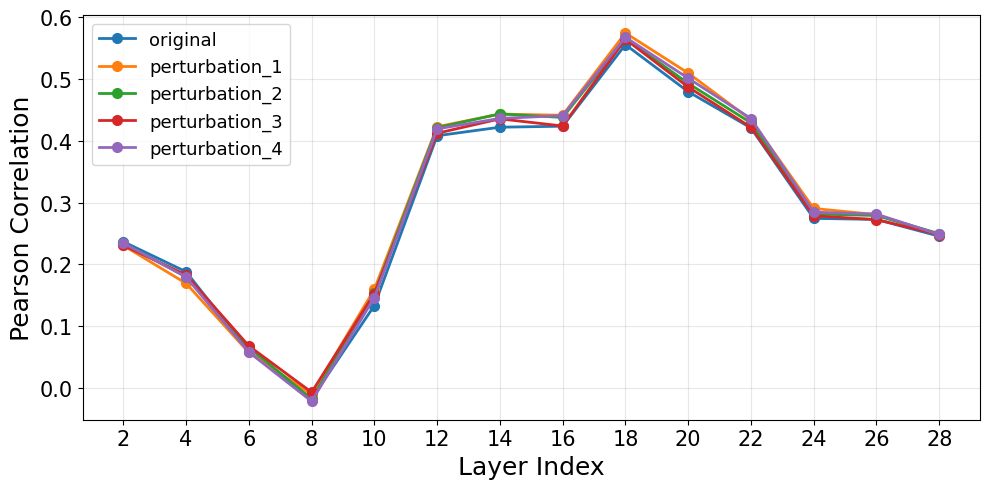

In [13]:
all_numeric_layers = set()
for rr in run_results.values():
    for layer in rr['layer_mean'].keys():
        if isinstance(layer, int):
            all_numeric_layers.add(layer)

layers_sorted = sorted(all_numeric_layers)
print('numeric layers:', layers_sorted)

plt.figure(figsize=(10, 5))

for run_name in RUN_DIRS.keys():
    if run_name not in run_results:
        continue
    lm = run_results[run_name]['layer_mean']
    y = [lm.get(layer, np.nan) for layer in layers_sorted]
    plt.plot(
        layers_sorted, y,
        marker='o',
        linewidth=2.0,
        markersize=7,
        label=run_name
    )

plt.xlabel('Layer Index', fontsize=18)
plt.ylabel('Pearson Correlation', fontsize=18)

plt.xticks(layers_sorted, fontsize=15)
plt.yticks(fontsize=15)

plt.grid(alpha=0.3)

plt.legend(fontsize=13)

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import json
import re
import numpy as np

layer12_base_dir = Path('/RobustPruner_2026/RobustPruner/glimpse_qwen_eval/token_scores')
layer12_run_dirs = {
    'original': layer12_base_dir / 'gqa_rand_seed42_20000',
    'concise_rephrase': layer12_base_dir / 'text_perturbations_concise_rephrase',
    'synonym_replacement': layer12_base_dir / 'text_perturbations_synonym_replacement',
    'sentence_structure_change': layer12_base_dir / 'text_perturbations_sentence_structure_change',
    'advanced_vocabulary': layer12_base_dir / 'text_perturbations_advanced_vocabulary',
}
layer12_target_layer = 12
layer12_file_glob = 'gqa_rand_seed42_20000_*.json'
layer12_output_dir = layer12_base_dir / 'layer12_token_stats_per_doc'

def layer12_numeric_suffix(filename: str) -> int:
    m = re.search(r'(\d+)\.json$', filename)
    return int(m.group(1)) if m else 10**18


def layer12_get_payload(sample_obj: dict, target_layer: int):
    per_layer_map = sample_obj.get('per_layer_text_to_visual', {}) or {}
    for key, payload in per_layer_map.items():
        if not isinstance(payload, dict):
            continue
        idx = payload.get('layer_index_1based')
        if idx is None:
            m = re.match(r'layer_(\d+)$', str(key))
            if m:
                idx = int(m.group(1))
        if idx == target_layer:
            return payload
    return None


def layer12_load_vectors(json_path: Path, target_layer: int):
    with open(json_path, 'r', encoding='utf-8') as f:
        obj = json.load(f)
    payload = layer12_get_payload(obj, target_layer)
    if payload is None:
        return None, None
    attn_vec = np.asarray(payload.get('text_to_visual_attention', []), dtype=np.float64)
    simi_vec = np.asarray(payload.get('text_to_visual_similarity', []), dtype=np.float64)
    return attn_vec, simi_vec


# collect file maps for 5 runs
layer12_run_filemaps = {}
for run_name, run_dir in layer12_run_dirs.items():
    files = sorted(run_dir.glob(layer12_file_glob), key=lambda p: layer12_numeric_suffix(p.name))
    layer12_run_filemaps[run_name] = {p.name: p for p in files}
    print(f'{run_name:14s}: {len(files)} files ({run_dir})')

# only process samples present in all runs
layer12_common_names = sorted(
    set.intersection(*[set(m.keys()) for m in layer12_run_filemaps.values()]),
    key=layer12_numeric_suffix,
)
print('common files across 5 runs:', len(layer12_common_names))

layer12_output_dir.mkdir(parents=True, exist_ok=True)

layer12_ok = 0
layer12_skipped = 0

for sample_name in layer12_common_names:
    attn_runs = []
    simi_runs = []
    invalid = False

    for run_name in layer12_run_dirs.keys():
        attn_vec, simi_vec = layer12_load_vectors(layer12_run_filemaps[run_name][sample_name], layer12_target_layer)
        if attn_vec is None or simi_vec is None or attn_vec.size == 0 or simi_vec.size == 0:
            invalid = True
            break
        attn_runs.append(attn_vec)
        simi_runs.append(simi_vec)

    if invalid:
        layer12_skipped += 1
        continue

    token_len = min([x.size for x in attn_runs + simi_runs])
    if token_len <= 0:
        layer12_skipped += 1
        continue

    attn_stack = np.stack([x[:token_len] for x in attn_runs], axis=0)
    simi_stack = np.stack([x[:token_len] for x in simi_runs], axis=0)

    attn_avg = np.mean(attn_stack, axis=0)
    attn_var = np.var(attn_stack, axis=0)
    simi_avg = np.mean(simi_stack, axis=0)
    simi_var = np.var(simi_stack, axis=0)

    m = re.search(r'(\d+)\.json$', sample_name)
    doc_id = int(m.group(1)) if m else None

    token_stats = {}
    for t in range(token_len):
        token_stats[str(t)] = {
            'attn_avg': float(attn_avg[t]),
            'attn_var': float(attn_var[t]),
            'simi_avg': float(simi_avg[t]),
            'simi_var': float(simi_var[t]),
        }

    out_obj = {
        'doc_id': doc_id,
        'token_stats': token_stats,
    }

    if doc_id is not None:
        out_name = f'{doc_id}.json'
    else:
        out_name = f'{Path(sample_name).stem}.json'

    out_path = layer12_output_dir / out_name
    with open(out_path, 'w', encoding='utf-8') as fout:
        json.dump(out_obj, fout, ensure_ascii=False)

    layer12_ok += 1

print('output dir:', layer12_output_dir)
print('processed:', layer12_ok, 'skipped:', layer12_skipped)

original      : 20000 files (/mnt/nvme/fjh/glimpse_qwen_eval/token_scores/Qwen2.5-VL-7B-Instruct/original)
perturbation_1: 20000 files (/mnt/nvme/fjh/glimpse_qwen_eval/token_scores/Qwen2.5-VL-7B-Instruct/perturbation_1)
perturbation_2: 20000 files (/mnt/nvme/fjh/glimpse_qwen_eval/token_scores/Qwen2.5-VL-7B-Instruct/perturbation_2)
perturbation_3: 20000 files (/mnt/nvme/fjh/glimpse_qwen_eval/token_scores/Qwen2.5-VL-7B-Instruct/perturbation_3)
perturbation_4: 20000 files (/mnt/nvme/fjh/glimpse_qwen_eval/token_scores/Qwen2.5-VL-7B-Instruct/perturbation_4)
common files across 5 runs: 20000
output dir: /mnt/nvme/fjh/glimpse_qwen_eval/token_scores/Qwen2.5-VL-7B-Instruct/layer12_token_stats_per_doc
processed: 20000 skipped: 0
